# Time Series: Advanced Assignment Part 4
## Time Series Comparison and Prediction

**Student Name(s):** Ariful Islam Riane (3981886), Pedro Fernandez Tonso (3983781)

**Group No:** 19

Answers to questions (a) to (f) of `time_series_assignment.pdf`. Questions (a) to (e) use the Kaggle Berkeley Earth country temperatures (taken from the OpenML mirror, dataset 40918) and (f) uses hourly Oslo data from the Open-Meteo archive. Both files are in `../databank/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tslearn.metrics import dtw, dtw_path
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.signal import periodogram
from sklearn.metrics import mean_squared_error, mean_absolute_error

DATA = Path.cwd().parent / "databank"
COUNTRIES = ['Norway', 'Finland', 'Singapore', 'Cambodia']

## (a) Data preparation [BASIC]

In [2]:
df = pd.read_csv(DATA / 'GlobalLandTemperaturesByCountry.csv', parse_dates=['dt'])
raw = df[df.Country.isin(COUNTRIES)].pivot(index='dt', columns='Country', values='AverageTemperature')[COUNTRIES]

def missing_summary(s):
    s = s[s.first_valid_index():]
    return {'first observation': s.index[0].date(), 'last observation': s.last_valid_index().date(),
            'missing after first obs.': s.isna().sum(), 'last missing month before 2013': s[:'2012'][s[:'2012'].isna()].index.max().date(),
            'missing 1900-2012': s['1900':'2012'].isna().sum()}

pd.DataFrame({c: missing_summary(raw[c]) for c in COUNTRIES}).T

,first observation,last observation,missing after first obs.,last missing month before 2013,missing 1900-2012
Norway,1743-11-01,2013-08-01,73,1752-09-01,0
Finland,1743-11-01,2013-08-01,73,1752-09-01,0
Singapore,1825-01-01,2013-08-01,213,1862-12-01,0
Cambodia,1825-01-01,2013-08-01,196,1862-12-01,0


Norway and Finland start in 1743 and Singapore and Cambodia in 1825. All gaps are early (the last one is in 1752 and 1862), except September 2013, which is empty everywhere. 1900-2012 is therefore complete for all four countries, no imputation is needed and every yearly mean covers 12 months. The time interpolation stays in as a safeguard.

In [3]:
monthly = raw.loc['1900':'2012'].interpolate(method='time').asfreq('MS')
assert monthly.notna().all().all()
yearly = monthly.resample('YS').mean()
monthly.shape, yearly.shape

((1356, 4), (113, 4))

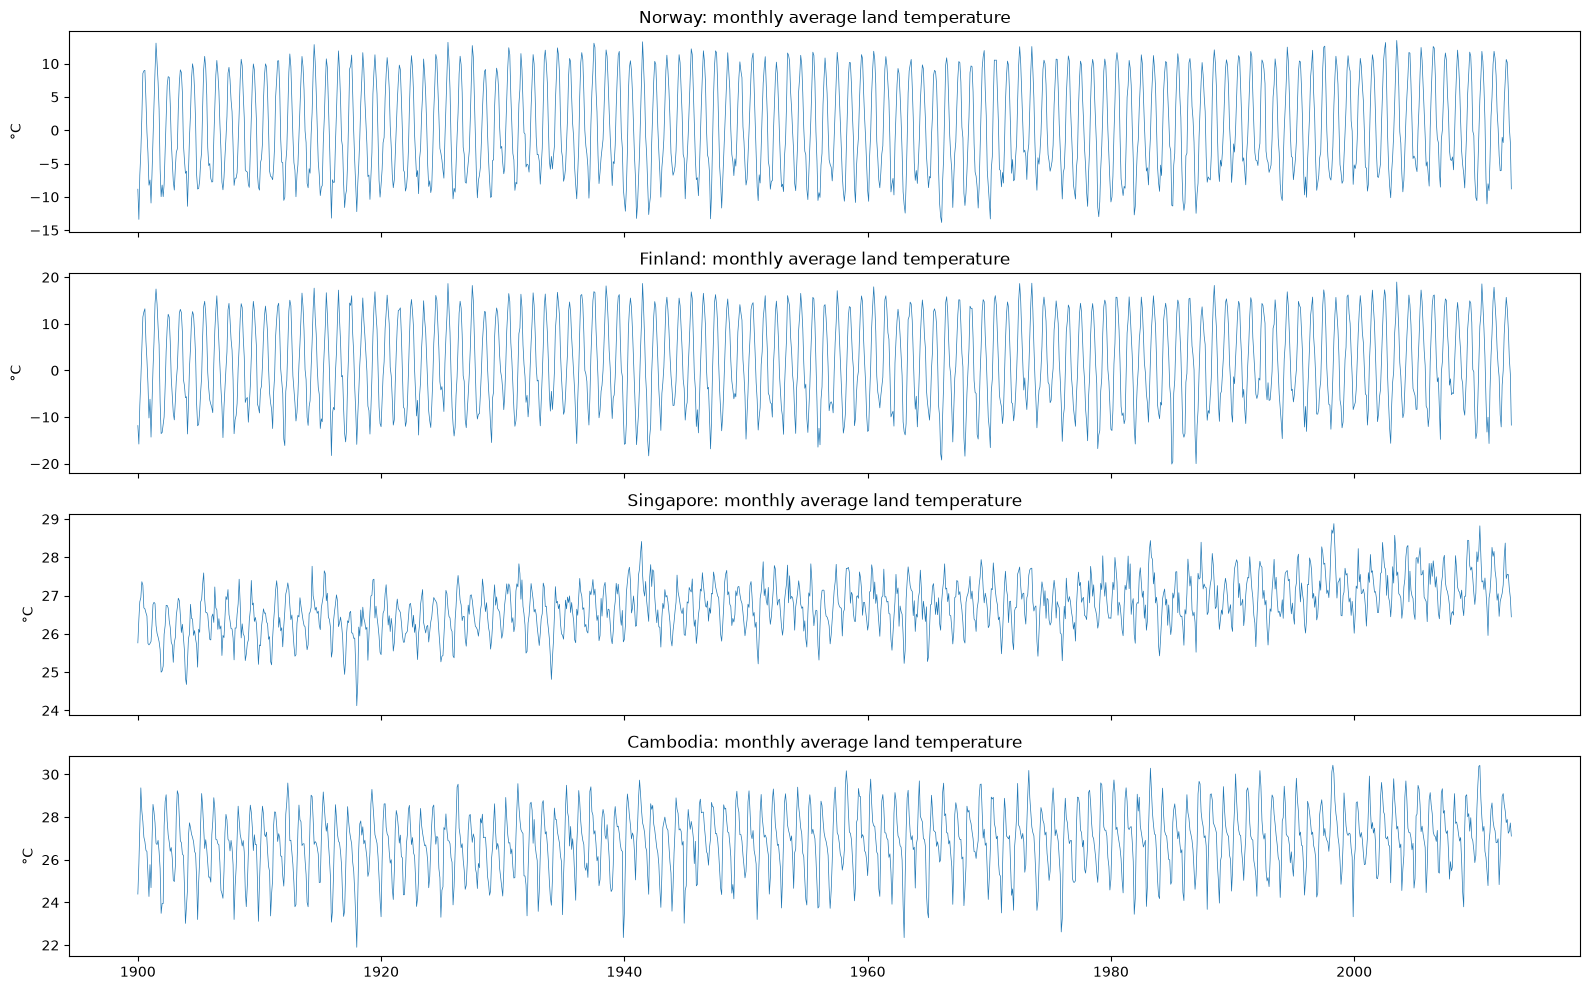

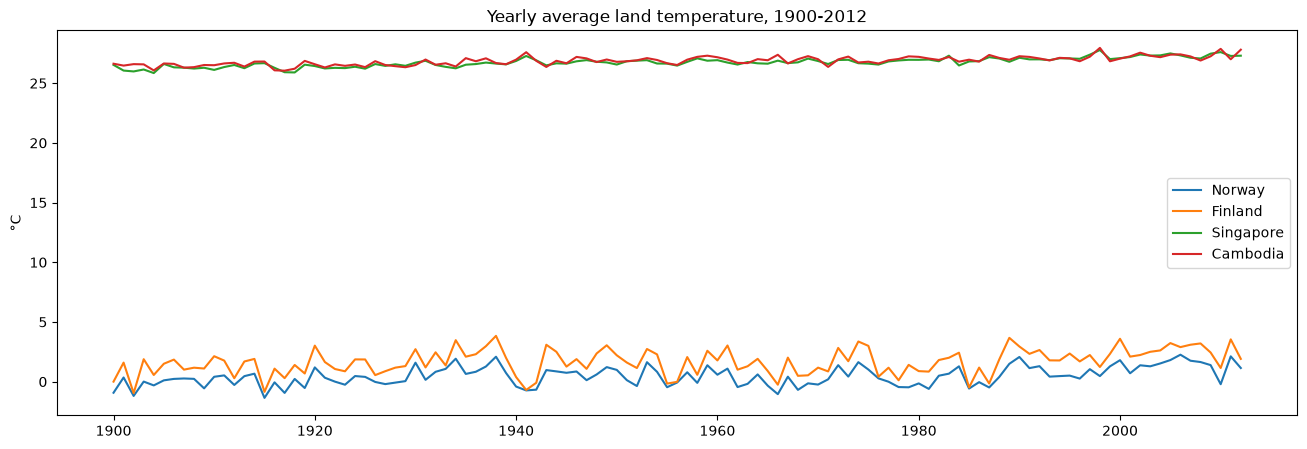

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
for ax, c in zip(axes, COUNTRIES):
    ax.plot(monthly.index, monthly[c], lw=0.5)
    ax.set_ylabel('°C')
    ax.set_title(f'{c}: monthly average land temperature')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(16, 5))
for c in COUNTRIES:
    ax.plot(yearly.index, yearly[c], label=c)
ax.set_ylabel('°C')
ax.set_title('Yearly average land temperature, 1900-2012')
ax.legend()
plt.show()

## (b) Comparison with DTW [REGULAR]

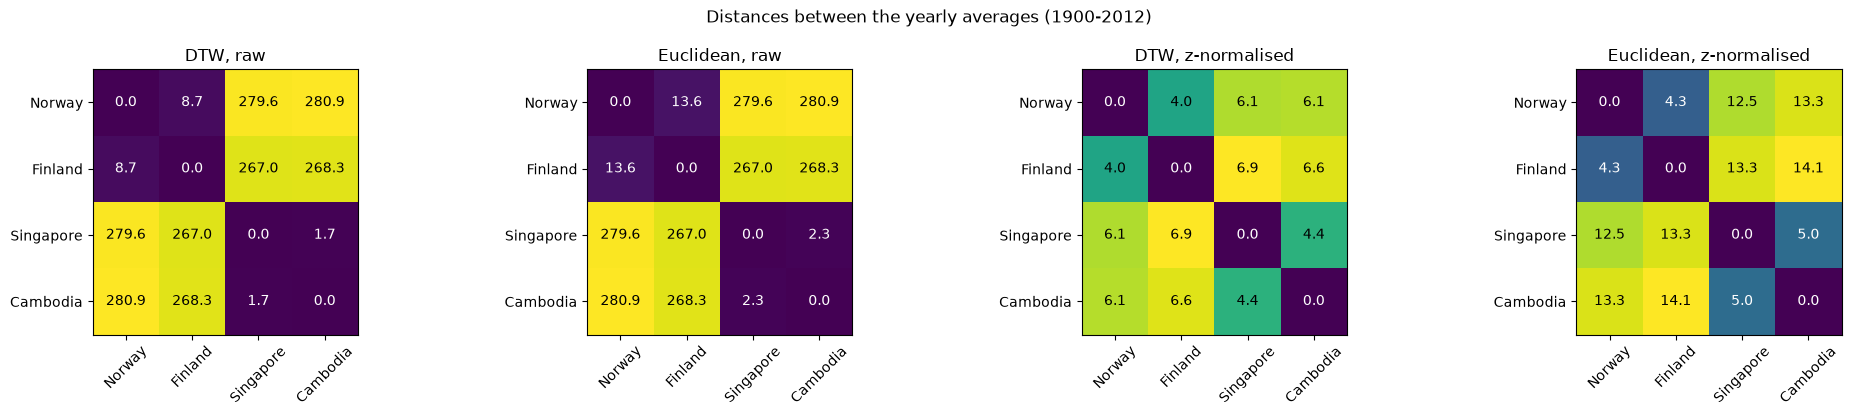

DTW, raw


Country,Norway,Finland,Singapore,Cambodia
Country,,,,
Norway,0.00,8.75,279.55,280.91
Finland,8.75,0.00,266.97,268.33
Singapore,279.55,266.97,0.00,1.74
Cambodia,280.91,268.33,1.74,0.00


Euclidean, raw


Country,Norway,Finland,Singapore,Cambodia
Country,,,,
Norway,0.00,13.57,279.55,280.91
Finland,13.57,0.00,266.97,268.33
Singapore,279.55,266.97,0.00,2.31
Cambodia,280.91,268.33,2.31,0.00


DTW, z-normalised


Country,Norway,Finland,Singapore,Cambodia
Country,,,,
Norway,0.00,4.03,6.07,6.14
Finland,4.03,0.00,6.90,6.56
Singapore,6.07,6.90,0.00,4.44
Cambodia,6.14,6.56,4.44,0.00


Euclidean, z-normalised


Country,Norway,Finland,Singapore,Cambodia
Country,,,,
Norway,0.00,4.29,12.46,13.34
Finland,4.29,0.00,13.34,14.12
Singapore,12.46,13.34,0.00,5.01
Cambodia,13.34,14.12,5.01,0.00


In [5]:
def znorm(s):
    return (s - s.mean()) / s.std()

def euclidean(a, b):
    return np.linalg.norm(a - b)

def pairwise(frame, metric):
    return pd.DataFrame([[metric(frame[a].values, frame[b].values) for b in frame] for a in frame],
                        index=frame.columns, columns=frame.columns)

def show_matrices(mats, title):
    fig, axes = plt.subplots(1, len(mats), figsize=(5 * len(mats), 4.2))
    for ax, (name, m) in zip(np.atleast_1d(axes), mats.items()):
        ax.imshow(m.values, cmap='viridis')
        ax.set_xticks(range(len(m)), m.columns, rotation=45)
        ax.set_yticks(range(len(m)), m.index)
        for i in range(len(m)):
            for j in range(len(m)):
                ax.text(j, i, f'{m.iat[i, j]:.1f}', ha='center', va='center',
                        color='white' if m.iat[i, j] < m.values.max() / 2 else 'black')
        ax.set_title(name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

yearly_z = yearly.apply(znorm)
dist_b = {'DTW, raw': pairwise(yearly, dtw),
          'Euclidean, raw': pairwise(yearly, euclidean),
          'DTW, z-normalised': pairwise(yearly_z, dtw),
          'Euclidean, z-normalised': pairwise(yearly_z, euclidean)}
show_matrices(dist_b, 'Distances between the yearly averages (1900-2012)')
for name, m in dist_b.items():
    print(name); display(m.round(2))

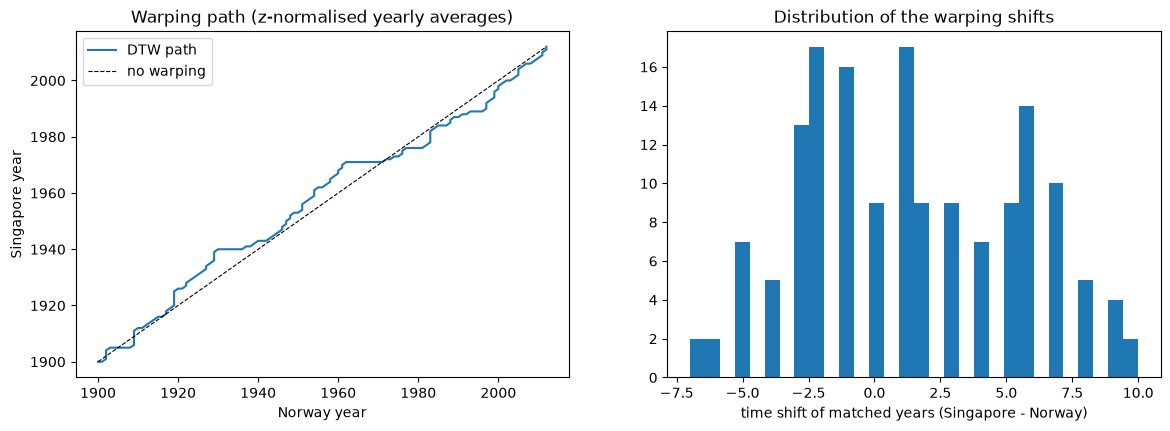

In [6]:
# Where does unconstrained DTW warp? Path for the z-normalised Norway-Singapore pair
path, _ = dtw_path(yearly_z['Norway'].values, yearly_z['Singapore'].values)
path = np.array(path)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(path[:, 0] + 1900, path[:, 1] + 1900, label='DTW path')
axes[0].plot([1900, 2012], [1900, 2012], 'k--', lw=0.8, label='no warping')
axes[0].set_xlabel('Norway year')
axes[0].set_ylabel('Singapore year')
axes[0].legend()
axes[0].set_title('Warping path (z-normalised yearly averages)')
axes[1].hist(path[:, 1] - path[:, 0], bins=30)
axes[1].set_xlabel('time shift of matched years (Singapore - Norway)')
axes[1].set_title('Distribution of the warping shifts')
plt.show()

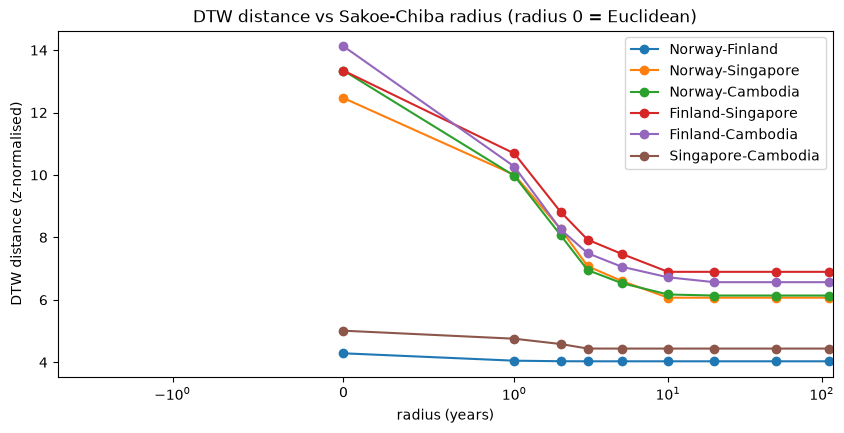

,Norway-Finland,Norway-Singapore,Norway-Cambodia,Finland-Singapore,Finland-Cambodia,Singapore-Cambodia
radius (years),,,,,,
0,4.29,12.46,13.34,13.34,14.12,5.01
1,4.05,10.00,9.97,10.69,10.27,4.75
2,4.03,8.27,8.07,8.82,8.25,4.58
3,4.03,7.08,6.95,7.93,7.49,4.44
5,4.03,6.60,6.53,7.47,7.06,4.44
10,4.03,6.07,6.17,6.90,6.72,4.44
20,4.03,6.07,6.14,6.90,6.56,4.44
50,4.03,6.07,6.14,6.90,6.56,4.44
112,4.03,6.07,6.14,6.90,6.56,4.44


In [7]:
# Effect of the Sakoe-Chiba warping window on the z-normalised DTW distance
radii = [0, 1, 2, 3, 5, 10, 20, 50, len(yearly) - 1]
pairs = [(a, b) for i, a in enumerate(COUNTRIES) for b in COUNTRIES[i + 1:]]
band = pd.DataFrame({f'{a}-{b}': [dtw(yearly_z[a].values, yearly_z[b].values, global_constraint='sakoe_chiba', sakoe_chiba_radius=r)
                                 for r in radii] for a, b in pairs}, index=pd.Index(radii, name='radius (years)'))
fig, ax = plt.subplots(figsize=(10, 4.5))
band.plot(ax=ax, marker='o')
ax.set_xscale('symlog', linthresh=1)
ax.set_ylabel('DTW distance (z-normalised)')
ax.set_title('DTW distance vs Sakoe-Chiba radius (radius 0 = Euclidean)')
plt.show()
band.round(2)

Raw data: DTW mostly measures the level difference (about 27 °C against 1 to 5 °C), so tropical-Nordic distances are around 270 to 280 for DTW and Euclidean alike. After z-normalisation it compares shape. Norway-Finland (4.03) and Singapore-Cambodia (4.44) are closest.

Warping is hardly meaningful here, since all series share the calendar and the drivers act in the same years. The Norway-Singapore path shifts by -7 to +10 years, which has no physical meaning, and DTW mostly lowers the distance of unrelated pairs by matching noise (12.5 to 6.1 for Norway-Singapore, 4.29 to 4.03 for Norway-Finland).

A Sakoe-Chiba band limits the shift. Radius 0 is the Euclidean distance, and the distance falls until the band is wide enough (radius 2 to 10 depending on the pair).

## (c) Stationarity [BASIC]

In [8]:
def adf(s):
    stat, pvalue, lags, nobs, *_ = adfuller(s)
    return {'ADF statistic': stat, 'p-value': pvalue, 'lags used': lags}

transforms = {'original': lambda s: s, 'first difference': lambda s: s.diff().dropna(), 'seasonal difference (lag 12)': lambda s: s.diff(12).dropna()}
adf_table = pd.DataFrame({(c, t): adf(f(monthly[c])) for c in COUNTRIES for t, f in transforms.items()}).T
adf_table['stationary at 5%'] = adf_table['p-value'] < 0.05
adf_table.style.format({'ADF statistic': '{:.2f}', 'p-value': '{:.2e}', 'lags used': '{:.0f}'})

/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)
/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)
/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends

/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)
/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)
/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends

/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)
/tmp/ipykernel_2351469/2974632573.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, lags, nobs, *_ = adfuller(s)


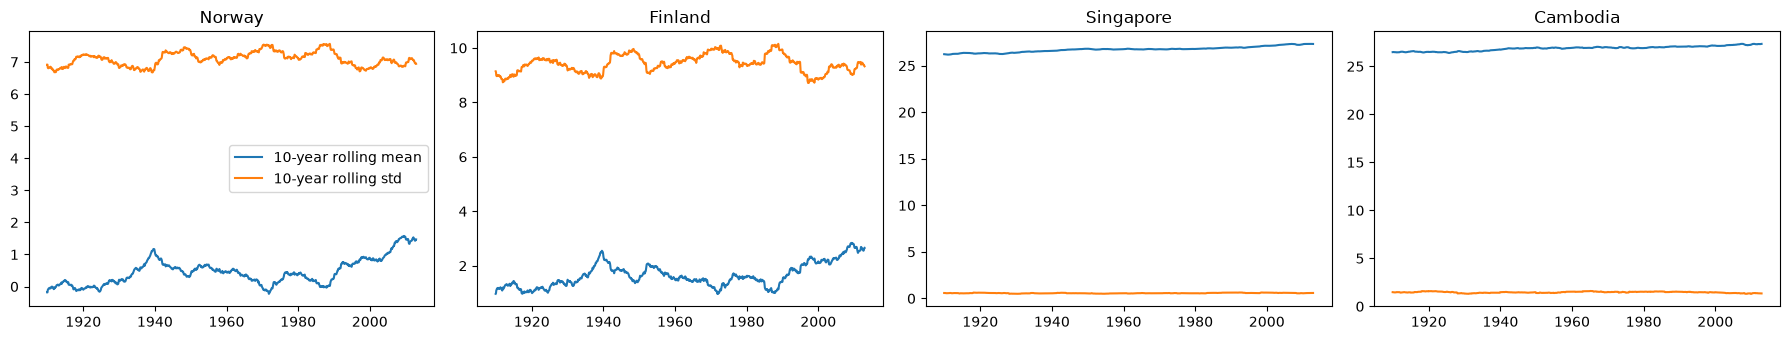

In [9]:
# Rolling statistics of the original series, to support the interpretation
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, c in zip(axes, COUNTRIES):
    ax.plot(monthly[c].rolling(120).mean(), label='10-year rolling mean')
    ax.plot(monthly[c].rolling(120).std(), label='10-year rolling std')
    ax.set_title(c)
axes[0].legend()
plt.tight_layout()
plt.show()

The ADF test rejects a unit root at 5% for Norway, Finland and Cambodia but not for Singapore (p = 0.09), whose small seasonal variance makes the warming trend relatively larger. After a first or a seasonal difference all series are stationary (p < 1e-20). A seasonal cycle does not create a unit root, so ADF passes most series as they are and has little power against the slow warming drift.

## (d) Trend and seasonality [REGULAR]

A lag-12 difference removes the yearly cycle and a first difference on top removes the remaining trend.

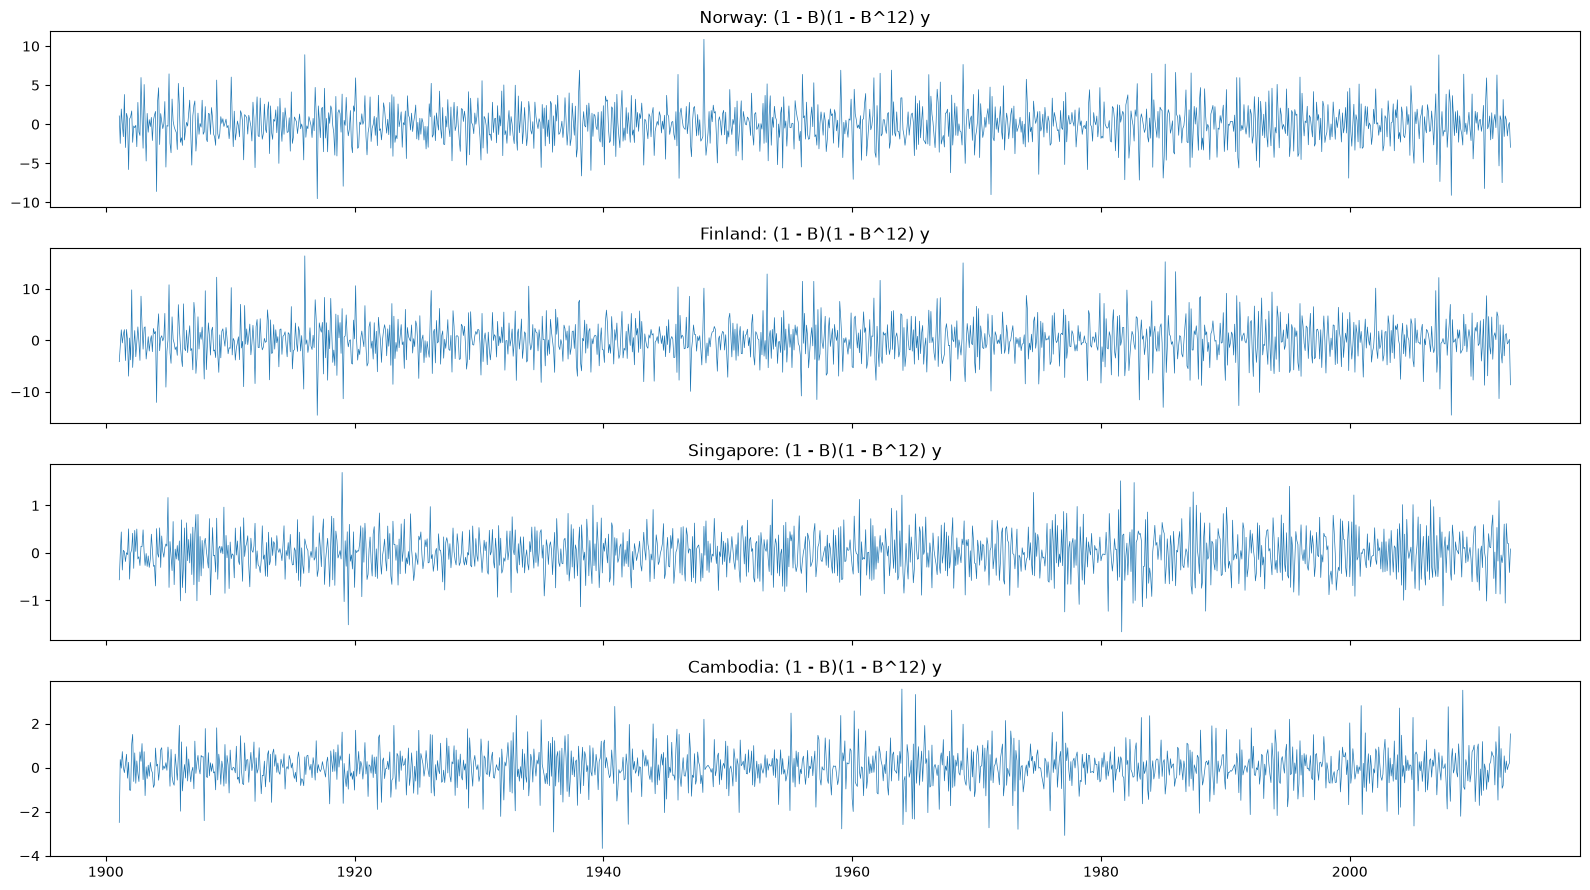

In [10]:
diffed = monthly.diff(12).diff().dropna()
fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=True)
for ax, c in zip(axes, COUNTRIES):
    ax.plot(diffed.index, diffed[c], lw=0.5)
    ax.set_title(f'{c}: (1 - B)(1 - B^12) y')
plt.tight_layout()
plt.show()

**(ii) Classical decomposition and (iii) STL decomposition**

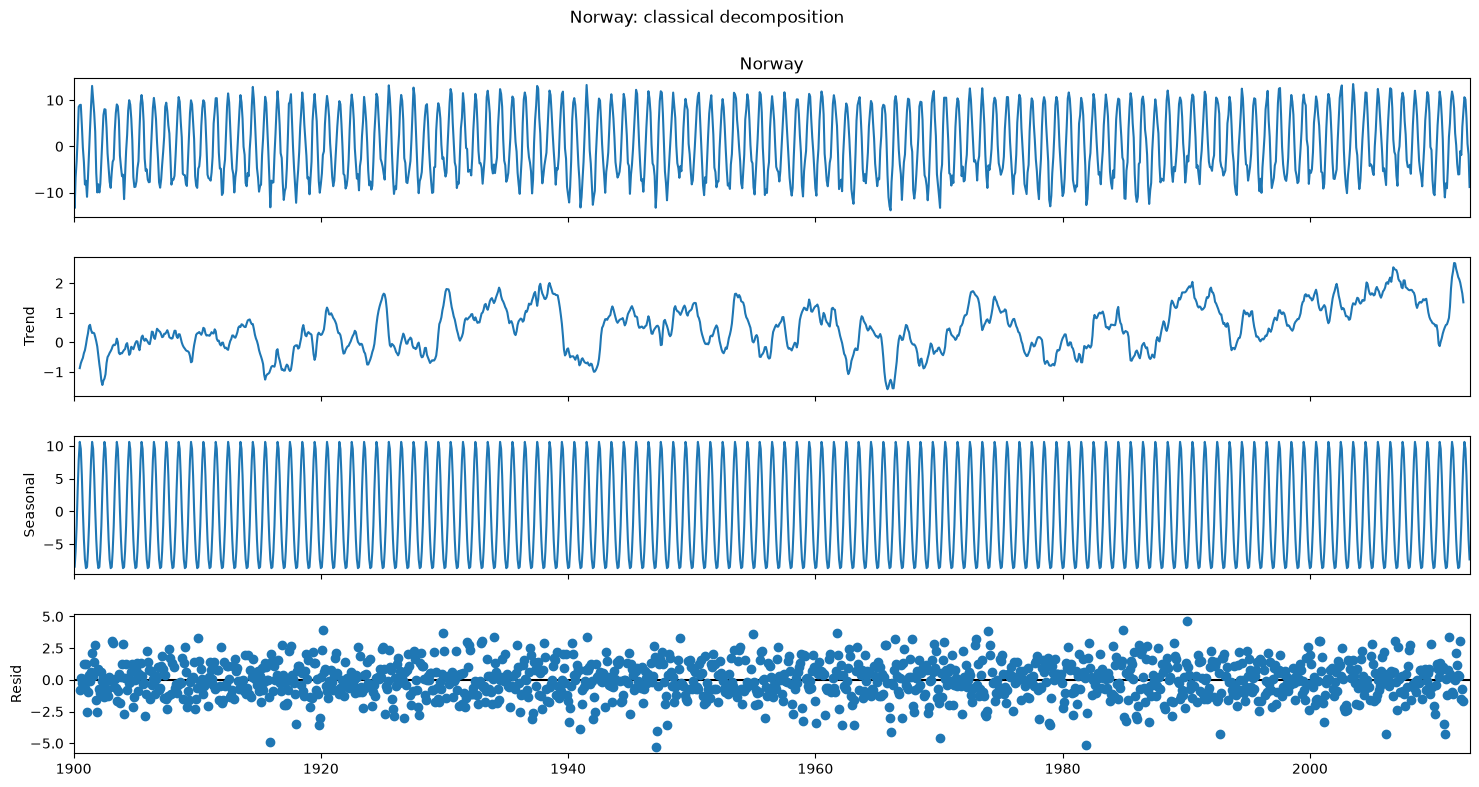

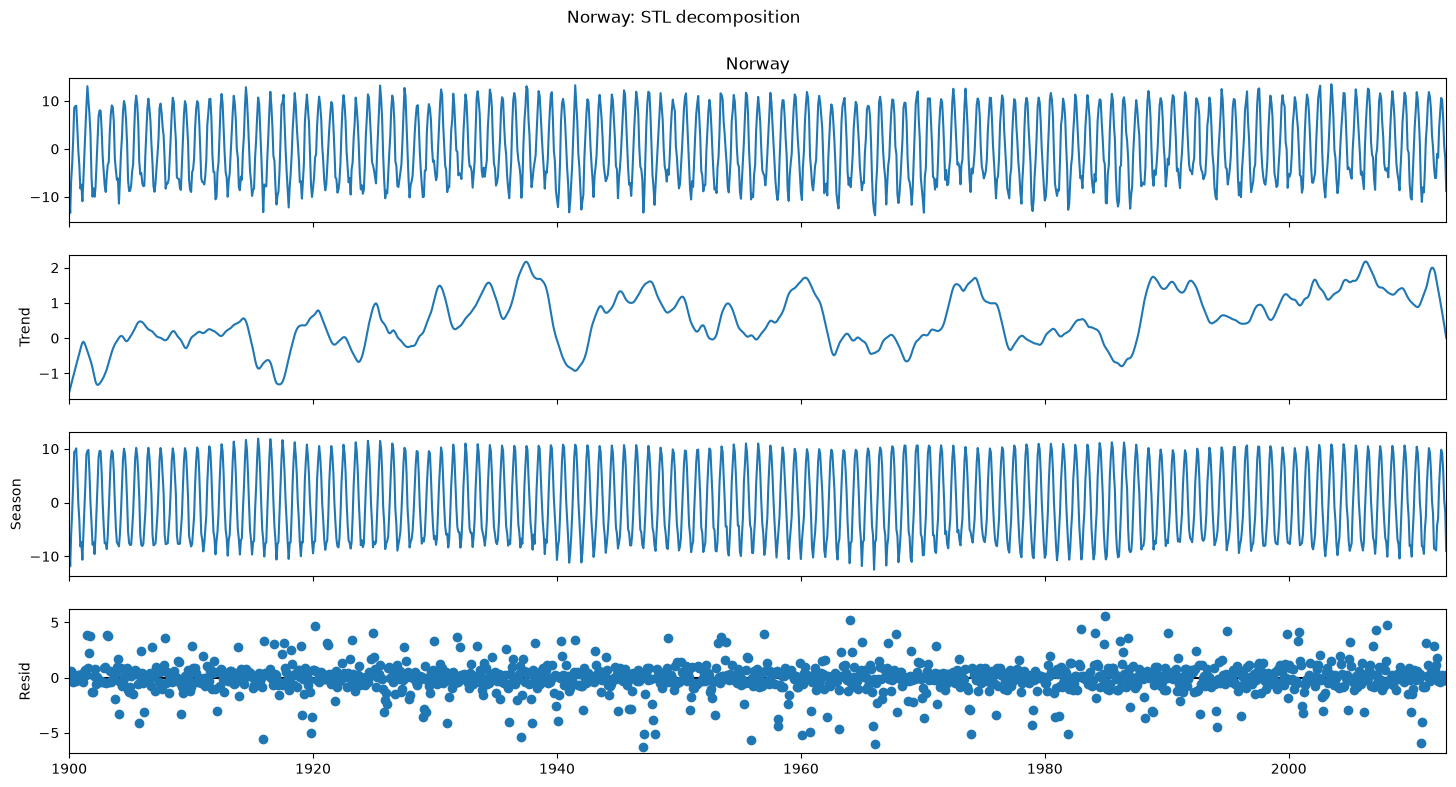

In [11]:
classical = {c: seasonal_decompose(monthly[c], model='additive', period=12) for c in COUNTRIES}
stl = {c: STL(monthly[c], period=12, robust=True).fit() for c in COUNTRIES}

fig = classical['Norway'].plot()
fig.set_size_inches(16, 8)
fig.suptitle('Norway: classical decomposition', y=1.01)
plt.show()
fig = stl['Norway'].plot()
fig.set_size_inches(16, 8)
fig.suptitle('Norway: STL decomposition', y=1.01)
plt.show()

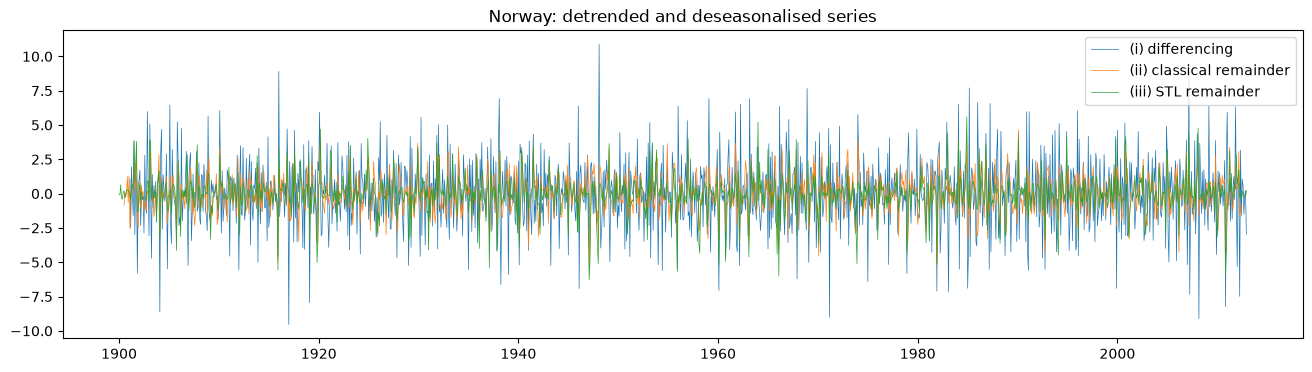

,(i) differencing,(ii) classical,(iii) STL
std of remainder,,,
Norway,2.531,1.419,1.330
Finland,3.899,2.149,2.045
Singapore,0.442,0.240,0.237
Cambodia,0.856,0.469,0.477


In [12]:
# Series with trend and seasonality removed by each method (Norway)
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(diffed.index, diffed['Norway'], lw=0.5, label='(i) differencing')
ax.plot(classical['Norway'].resid, lw=0.5, label='(ii) classical remainder')
ax.plot(stl['Norway'].resid, lw=0.5, label='(iii) STL remainder')
ax.set_title('Norway: detrended and deseasonalised series')
ax.legend()
plt.show()
pd.DataFrame({'(i) differencing': diffed.std(), '(ii) classical': pd.DataFrame({c: classical[c].resid for c in COUNTRIES}).std(),
              '(iii) STL': pd.DataFrame({c: stl[c].resid for c in COUNTRIES}).std()}).round(3).rename_axis('std of remainder')

Average STL seasonal profiles of the first and last 30 years against the classical profile, and the yearly amplitude of the STL seasonal component.

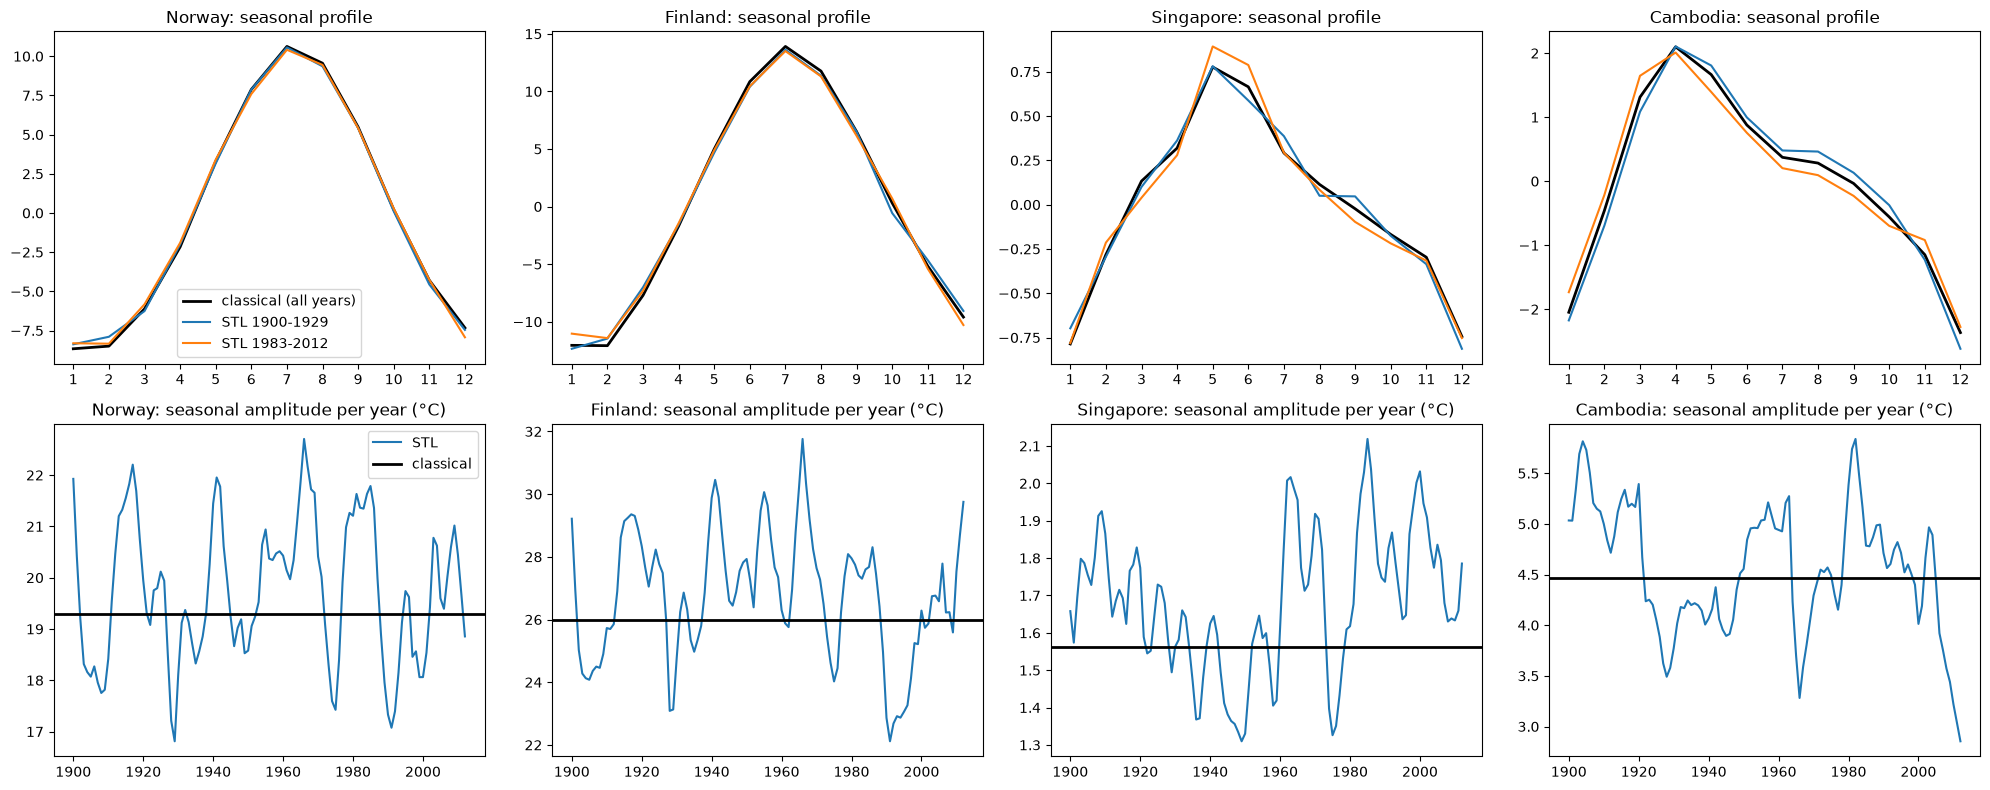

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
months = np.arange(1, 13)
for k, c in enumerate(COUNTRIES):
    seas_stl = stl[c].seasonal
    axes[0, k].plot(months, classical[c].seasonal[:12].values, 'k-', lw=2, label='classical (all years)')
    axes[0, k].plot(months, seas_stl['1900':'1929'].groupby(seas_stl['1900':'1929'].index.month).mean(), label='STL 1900-1929')
    axes[0, k].plot(months, seas_stl['1983':'2012'].groupby(seas_stl['1983':'2012'].index.month).mean(), label='STL 1983-2012')
    axes[0, k].set_title(f'{c}: seasonal profile')
    axes[0, k].set_xticks(months)
    amp = seas_stl.groupby(seas_stl.index.year).agg(lambda s: s.max() - s.min())
    axes[1, k].plot(amp.index, amp.values, label='STL')
    axes[1, k].axhline(np.ptp(classical[c].seasonal[:12]), color='k', lw=2, label='classical')
    axes[1, k].set_title(f'{c}: seasonal amplitude per year (°C)')
axes[0, 0].legend()
axes[1, 0].legend()
plt.tight_layout()
plt.show()

In the Nordic countries the STL profiles of 1900-1929 and 1983-2012 almost coincide with the classical one, and the yearly amplitude fluctuates without a trend, so a fixed seasonal pattern is a good approximation. In the tropics the cycle is weak and varies more in relative terms (Cambodia's shrinks near the end of the period). STL leaves a slightly smaller remainder for Norway and Finland.

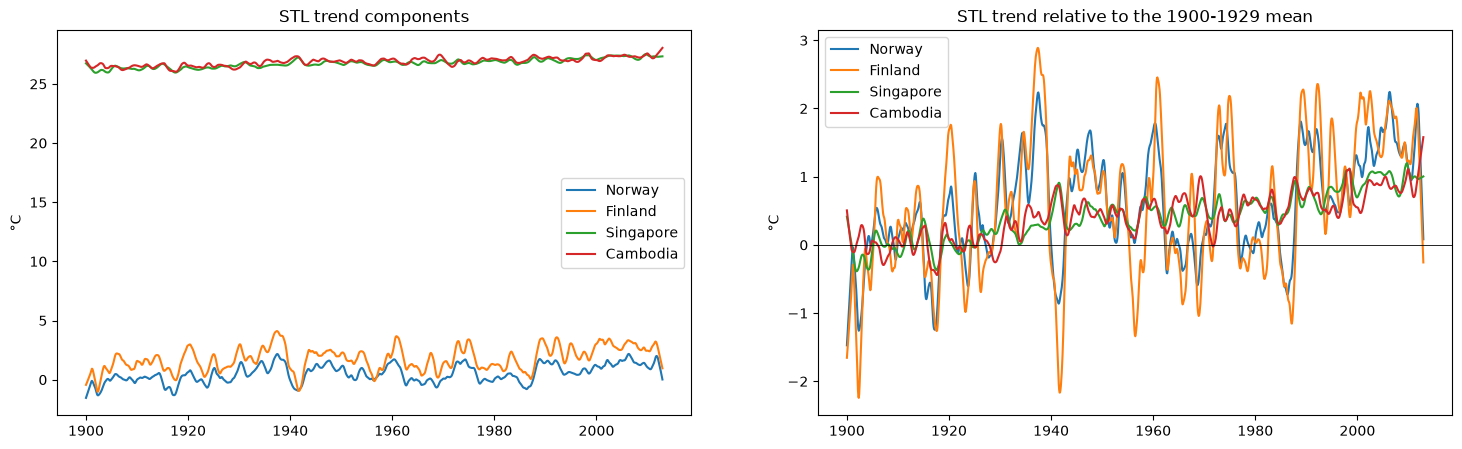

,trend 1983-2012 minus 1900-1929 (°C),linear slope 1900-2012 (°C / century),linear slope 1970-2012 (°C / century)
Norway,1.03,0.98,3.35
Finland,1.18,1.03,3.37
Singapore,0.82,0.97,1.67
Cambodia,0.75,0.80,1.35


In [14]:
trends = pd.DataFrame({c: stl[c].trend for c in COUNTRIES})
anomaly = trends - trends['1900':'1929'].mean()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for c in COUNTRIES:
    axes[0].plot(trends.index, trends[c], label=c)
    axes[1].plot(anomaly.index, anomaly[c], label=c)
axes[0].set_title('STL trend components')
axes[0].set_ylabel('°C')
axes[1].set_title('STL trend relative to the 1900-1929 mean')
axes[1].set_ylabel('°C')
axes[1].axhline(0, color='k', lw=0.6)
for ax in axes: ax.legend()
plt.show()

years = yearly.index.year.values
warming = pd.DataFrame({
    'trend 1983-2012 minus 1900-1929 (°C)': trends['1983':'2012'].mean() - trends['1900':'1929'].mean(),
    'linear slope 1900-2012 (°C / century)': yearly.apply(lambda s: 100 * np.polyfit(years, s.values, 1)[0]),
    'linear slope 1970-2012 (°C / century)': yearly['1970':].apply(lambda s: 100 * np.polyfit(years[years >= 1970], s.values, 1)[0]),
})
warming.round(2)

All four trends rise: the 1983-2012 mean is 0.75 to 1.18 °C above 1900-1929. The warming accelerated: the linear slope is about 1 °C per century over the full period but 3.4 °C per century since 1970 for Norway and Finland, against 1.7 and 1.4 for Singapore and Cambodia. High latitudes warm about twice as fast.

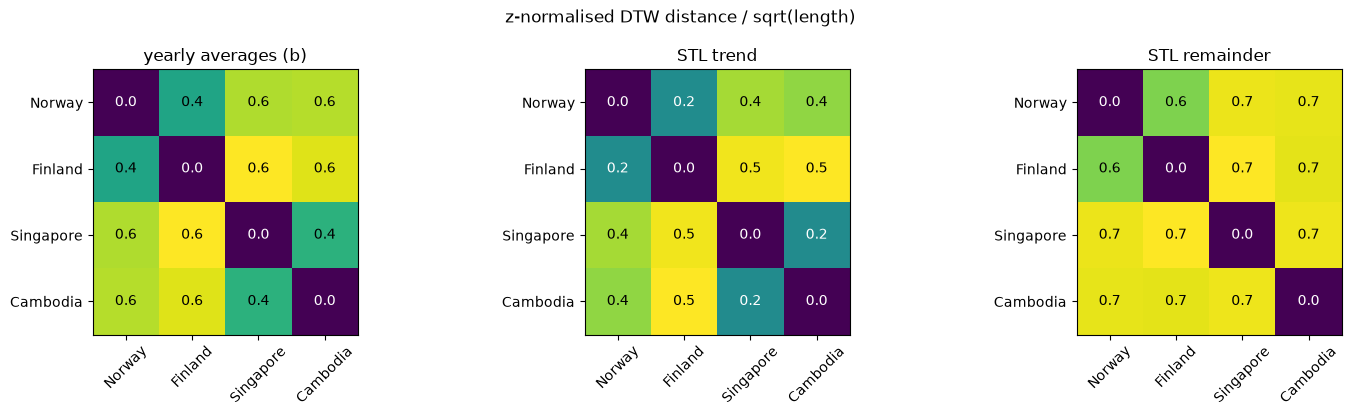

,yearly averages (b),STL trend,STL remainder,remainder correlation
Norway-Finland,0.379,0.250,0.560,0.766
Norway-Singapore,0.571,0.447,0.675,0.027
Norway-Cambodia,0.577,0.429,0.670,0.061
Finland-Singapore,0.649,0.505,0.696,0.008
Finland-Cambodia,0.618,0.515,0.668,0.030
Singapore-Cambodia,0.417,0.248,0.677,0.312


In [15]:
# DTW on the STL trends and remainders. Monthly series are 12 times longer than the yearly series of (b), so all
# z-normalised distances are divided by sqrt(length) to make the three comparisons directly comparable.
remainders = pd.DataFrame({c: stl[c].resid for c in COUNTRIES})
per_len = lambda frame, metric: pairwise(frame.apply(znorm), metric) / np.sqrt(len(frame))
dist_d = {'yearly averages (b)': per_len(yearly, dtw),
          'STL trend': per_len(trends, dtw),
          'STL remainder': per_len(remainders, dtw)}
show_matrices(dist_d, 'z-normalised DTW distance / sqrt(length)')

summary = pd.DataFrame({name: {f'{a}-{b}': m.loc[a, b] for a, b in pairs} for name, m in dist_d.items()})
summary['remainder correlation'] = [remainders[a].corr(remainders[b]) for a, b in pairs]
summary.round(3)

Distances are divided by the square root of the series length to compare monthly and yearly series. On the trends the groupings of (b) hold (Norway-Finland and Singapore-Cambodia at 0.25, cross-region 0.43 to 0.52). On the remainders almost all pairs sit near 0.67, except Norway-Finland (0.56, correlation 0.77), which share weather. The similarity in (b) comes from the trend, and month-to-month anomalies are alike only for neighbours.

## (e) Forecast comparison [REGULAR]

We use Norway and hold out the last 24 months (2011-2012).

In [16]:
y = monthly['Norway']
train, test = y[:-24], y[-24:]

# seasonal naive
fc_naive = pd.Series(np.tile(train[-12:].values, 2), index=test.index)

# Holt-Winters
hw = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit()
fc_hw = hw.forecast(24)
print(f'train: {train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m}, test: {test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m}')
print(f'Norway temperature range in training data: {train.min():.1f} to {train.max():.1f} °C')

train: 1900-01 to 2010-12, test: 2011-01 to 2012-12
Norway temperature range in training data: -13.8 to 13.5 °C


We use an additive season, since the yearly swing of about 19 °C does not grow with the level, and a multiplicative one would fail for Celsius data that cross zero.

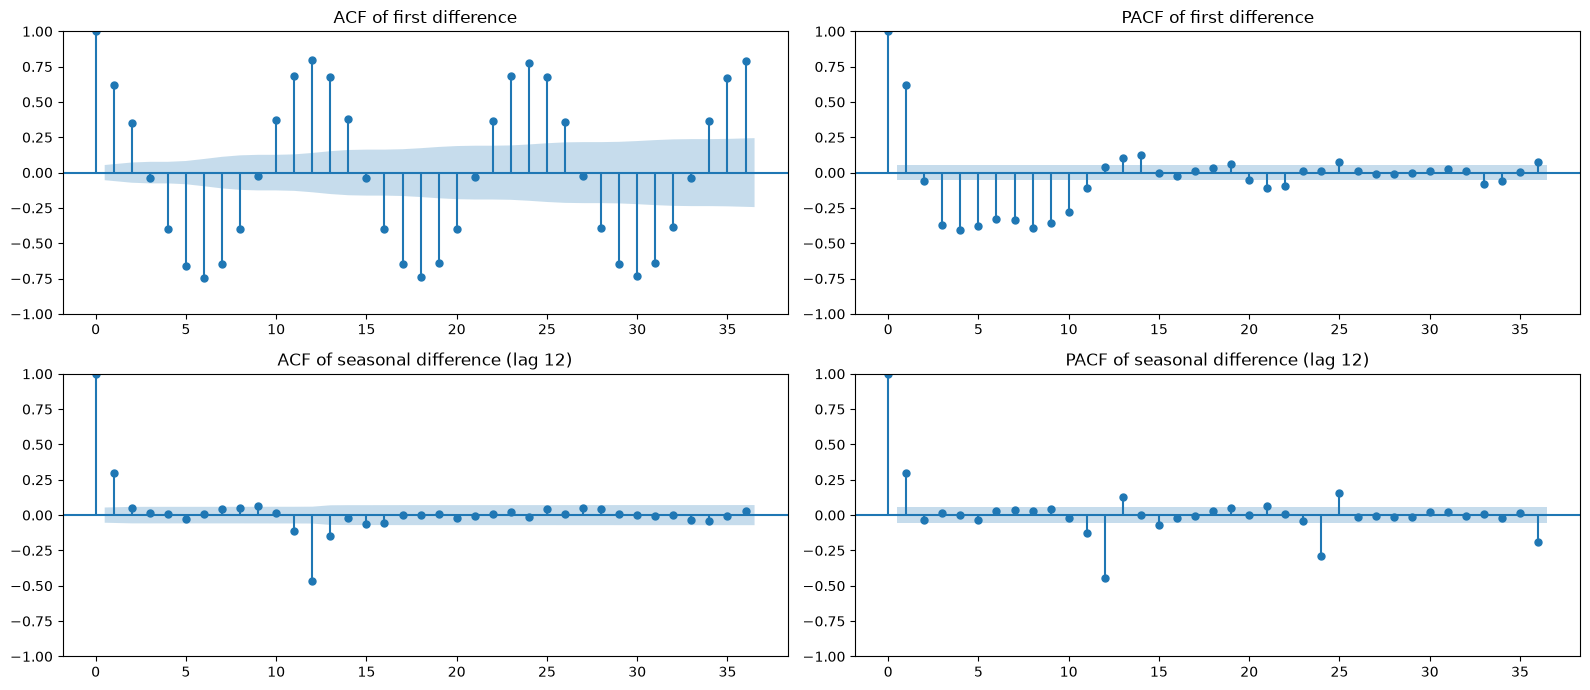

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
plot_acf(train.diff().dropna(), lags=36, ax=axes[0, 0], title='ACF of first difference')
plot_pacf(train.diff().dropna(), lags=36, ax=axes[0, 1], title='PACF of first difference')
plot_acf(train.diff(12).dropna(), lags=36, ax=axes[1, 0], title='ACF of seasonal difference (lag 12)')
plot_pacf(train.diff(12).dropna(), lags=36, ax=axes[1, 1], title='PACF of seasonal difference (lag 12)')
plt.tight_layout()
plt.show()

The ACF of the differenced data oscillates with period 12 and the PACF is a damped sinusoid after a large first value, the signature of an AR pair with complex roots at period 12, so p = 2. We take d = 1 as in the hint and q = 2 for the remaining correlation. A seasonal term would fit better (the lag-12 difference has an ACF spike of -0.47), but the assignment asks for a plain ARIMA.

In [18]:
ARIMA_ORDER = (2, 1, 2)
ar = ARIMA(train, order=ARIMA_ORDER).fit()
print(ar.summary().tables[1])
fc_ar = ar.forecast(24)

# For reference only: the AR polynomial roots show which periodicity the fitted ARIMA can reproduce
roots = ar.arroots
print('AR roots |z|:', np.round(np.abs(roots), 3))
print('implied periods (months):', np.round(2 * np.pi / np.abs(np.angle(roots[np.abs(np.angle(roots)) > 1e-6])), 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.7249      0.003    555.990      0.000       1.719       1.731
ar.L2         -0.9922      0.003   -351.998      0.000      -0.998      -0.987
ma.L1         -1.7897      0.011   -170.078      0.000      -1.810      -1.769
ma.L2          0.9310      0.011     88.315      0.000       0.910       0.952
sigma2         3.4658      0.124     28.000      0.000       3.223       3.708
AR roots |z|: [1.004 1.004]
implied periods (months): [11.99 11.99]


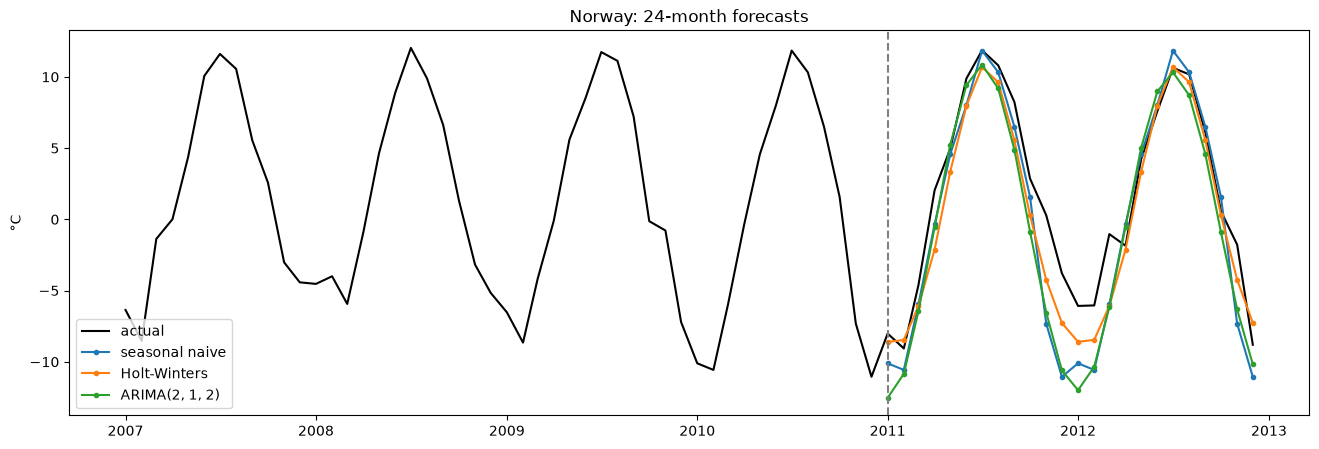

,RMSE,MAE
seasonal naive,3.133,2.262
Holt-Winters,2.271,1.791
"ARIMA(2, 1, 2)",3.349,2.683


In [19]:
forecasts = {'seasonal naive': fc_naive, 'Holt-Winters': fc_hw, f'ARIMA{ARIMA_ORDER}': fc_ar}
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(y['2007':].index, y['2007':], color='black', label='actual')
for name, fc in forecasts.items():
    ax.plot(fc.index, fc, marker='.', label=name)
ax.axvline(test.index[0], color='grey', ls='--')
ax.set_ylabel('°C')
ax.set_title('Norway: 24-month forecasts')
ax.legend()
plt.show()

pd.DataFrame({name: {'RMSE': np.sqrt(mean_squared_error(test, fc)), 'MAE': mean_absolute_error(test, fc)}
              for name, fc in forecasts.items()}).T.round(3)

Holt-Winters is best (RMSE 2.27) and beats the seasonal naive baseline (3.13) by 27%. ARIMA(2,1,2) does not (3.35). Winter 2011/12 was mild after a cold 2010/11, so models that repeat the last cycle overshoot the cold, and with only 24 test points the ranking is fragile.

ARIMA captures the period (the AR roots imply 11.99 months) but only as a sinusoid with fixed shape, anchored on the last observations and hardly damped. Holt-Winters updates 12 seasonal indices every year, so it follows the real shape of the cycle.

## (f) Multiple seasonality [ADVANCED]

Hourly `temperature_2m` for Oslo (59.91 N, 10.75 E), 2022-01-01 to 2024-12-31, from Open-Meteo (GMT).

In [20]:
print(open(DATA / 'oslo_hourly_temperature_2022_2024.csv').read(200))
yh = pd.read_csv(DATA / 'oslo_hourly_temperature_2022_2024.csv', skiprows=3, parse_dates=['time'], index_col='time').iloc[:, 0].asfreq('h')
assert yh.notna().all()
yh.describe()

latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
59.8594,10.808314,9.0,0,GMT,GMT

time,temperature_2m (°C)
2022-01-01T00:00,0.2
2022-01-01T01:00,-0.4
2022-01-01T02:00,0.0


count    26304.000000
mean         7.380049
std          8.652007
min        -27.200000
25%          1.100000
50%          7.300000
75%         14.600000
max         31.200000
Name: temperature_2m (°C), dtype: float64

**1. Seasonal periods**

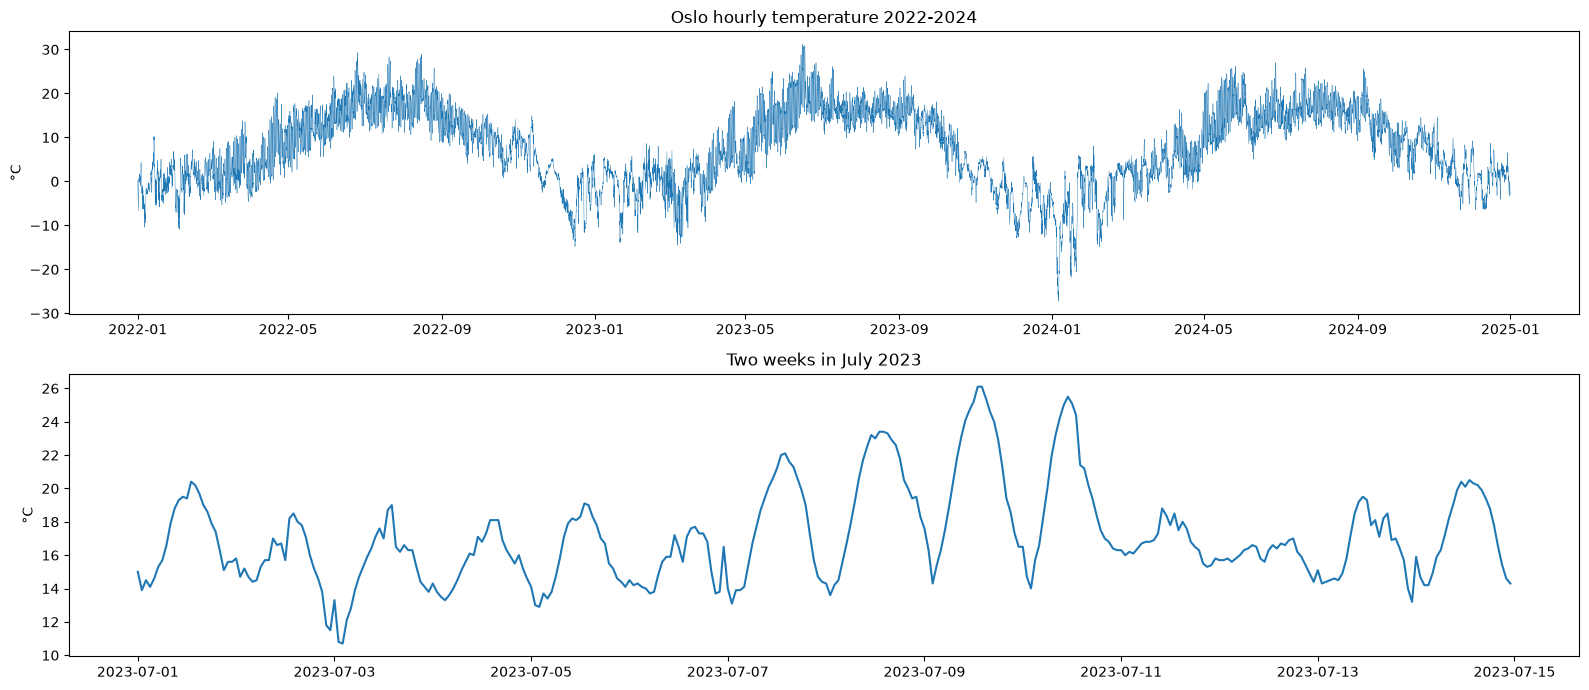

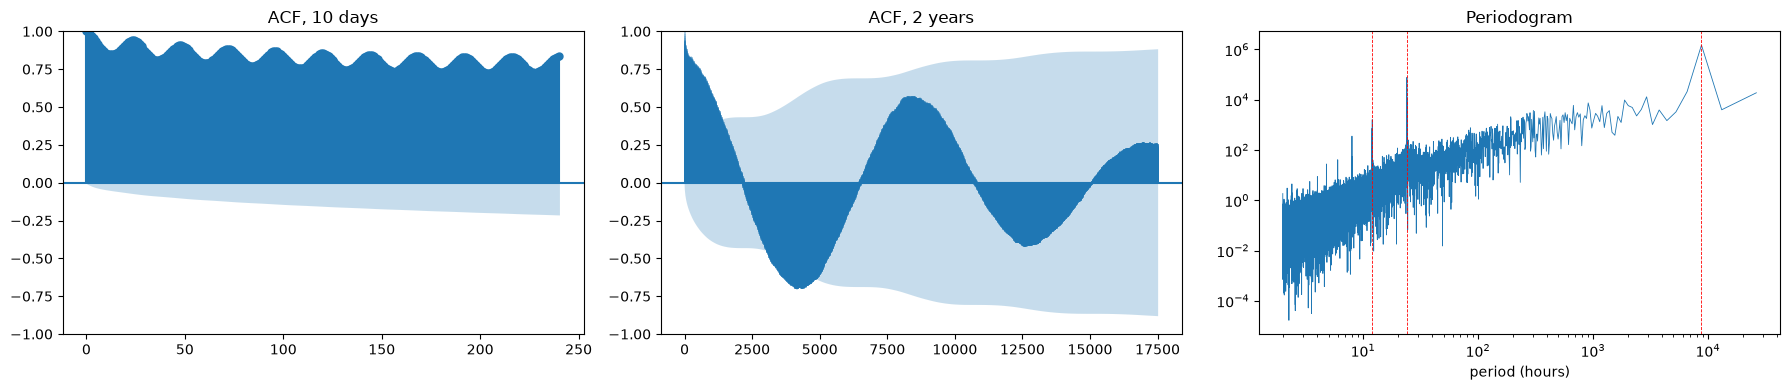

,period (hours),power,period (days)
2,8768.00,1495822.69,365.33
1095,24.00,77496.32,1.00
3,6576.00,21035.70,274.00
0,26304.00,18928.03,1096.00
8,2922.67,13082.36,121.78
1098,23.93,12418.41,1.00
1092,24.07,10484.97,1.00
13,1878.86,9731.85,78.29


In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 7))
axes[0].plot(yh.index, yh, lw=0.3)
axes[0].set_title('Oslo hourly temperature 2022-2024')
week = yh['2023-07-01':'2023-07-14']
axes[1].plot(week.index, week)
axes[1].set_title('Two weeks in July 2023')
for ax in axes: ax.set_ylabel('°C')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(yh, lags=24 * 10, ax=axes[0], title='ACF, 10 days')
plot_acf(yh, lags=24 * 365 * 2, ax=axes[1], title='ACF, 2 years', marker='', vlines_kwargs={'lw': 0.3})
f, p = periodogram(yh.values, detrend='linear')
axes[2].loglog(1 / f[1:], p[1:], lw=0.6)
axes[2].set_xlabel('period (hours)')
axes[2].set_title('Periodogram')
for period in [12, 24, 24 * 365]:
    axes[2].axvline(period, color='red', ls='--', lw=0.6)
plt.tight_layout()
plt.show()

peaks = pd.DataFrame({'period (hours)': 1 / f[1:], 'power': p[1:]}).nlargest(8, 'power')
peaks['period (days)'] = peaks['period (hours)'] / 24
peaks.round(2)

The periodogram peaks at about 8,768 h (the yearly cycle) and 24 h (daily), with a small harmonic at 12 h. The ACF shows the same two cycles. The seasonal periods are therefore 24 h and 8,760 h.

**2. MSTL vs single STL**

MSTL is slow with an 8,760 h period, so the trend and low-pass smoothers are evaluated every 24 hours (`trend_jump`, `low_pass_jump`), which gives practically the same components in about 30 seconds.

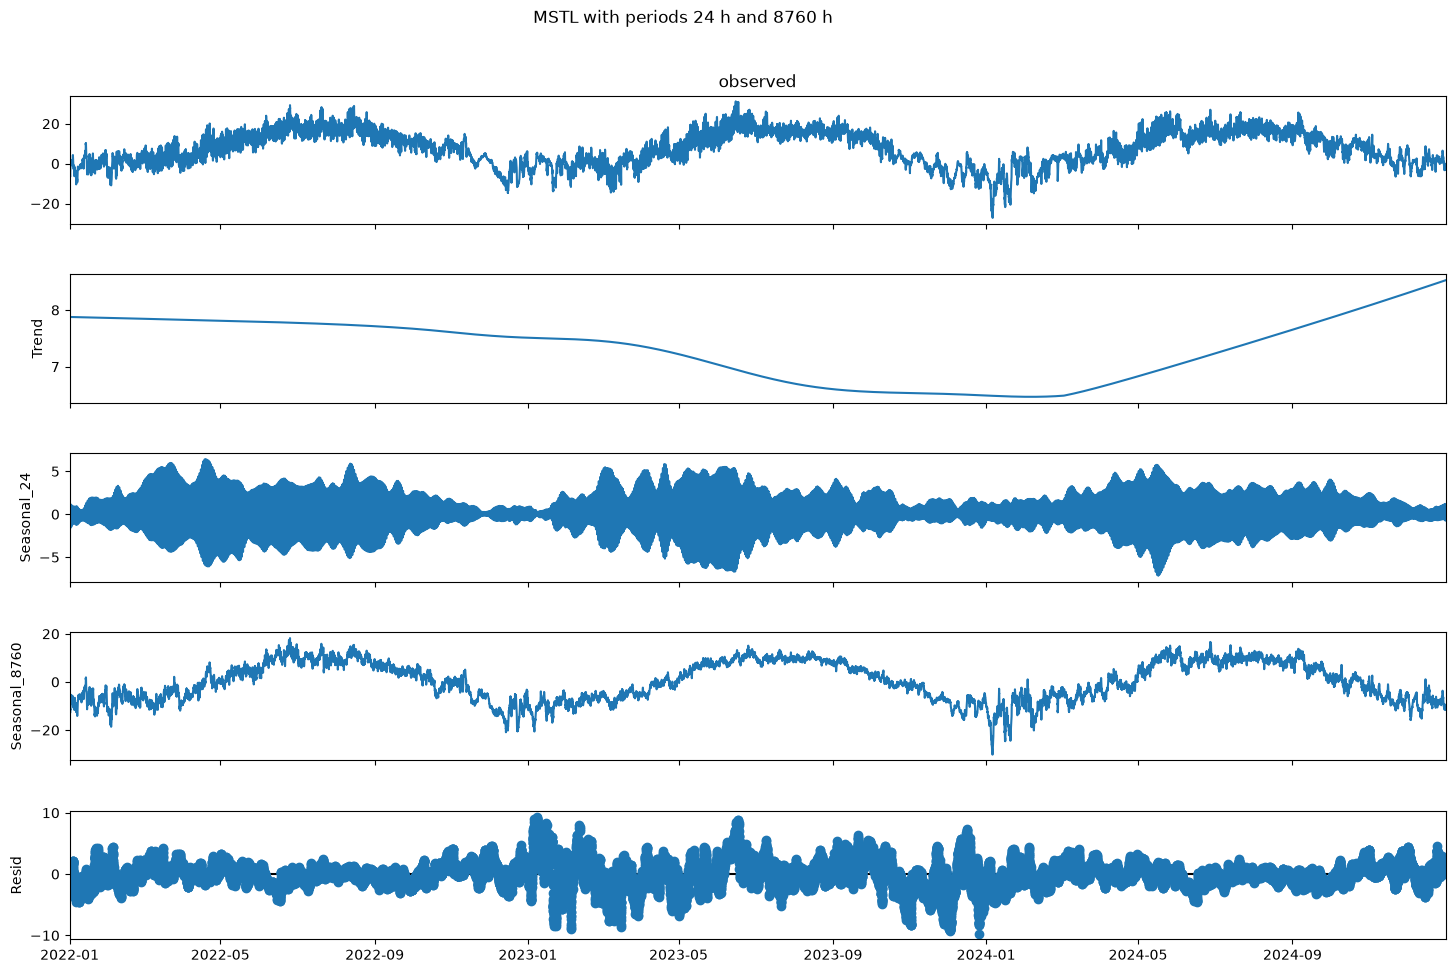

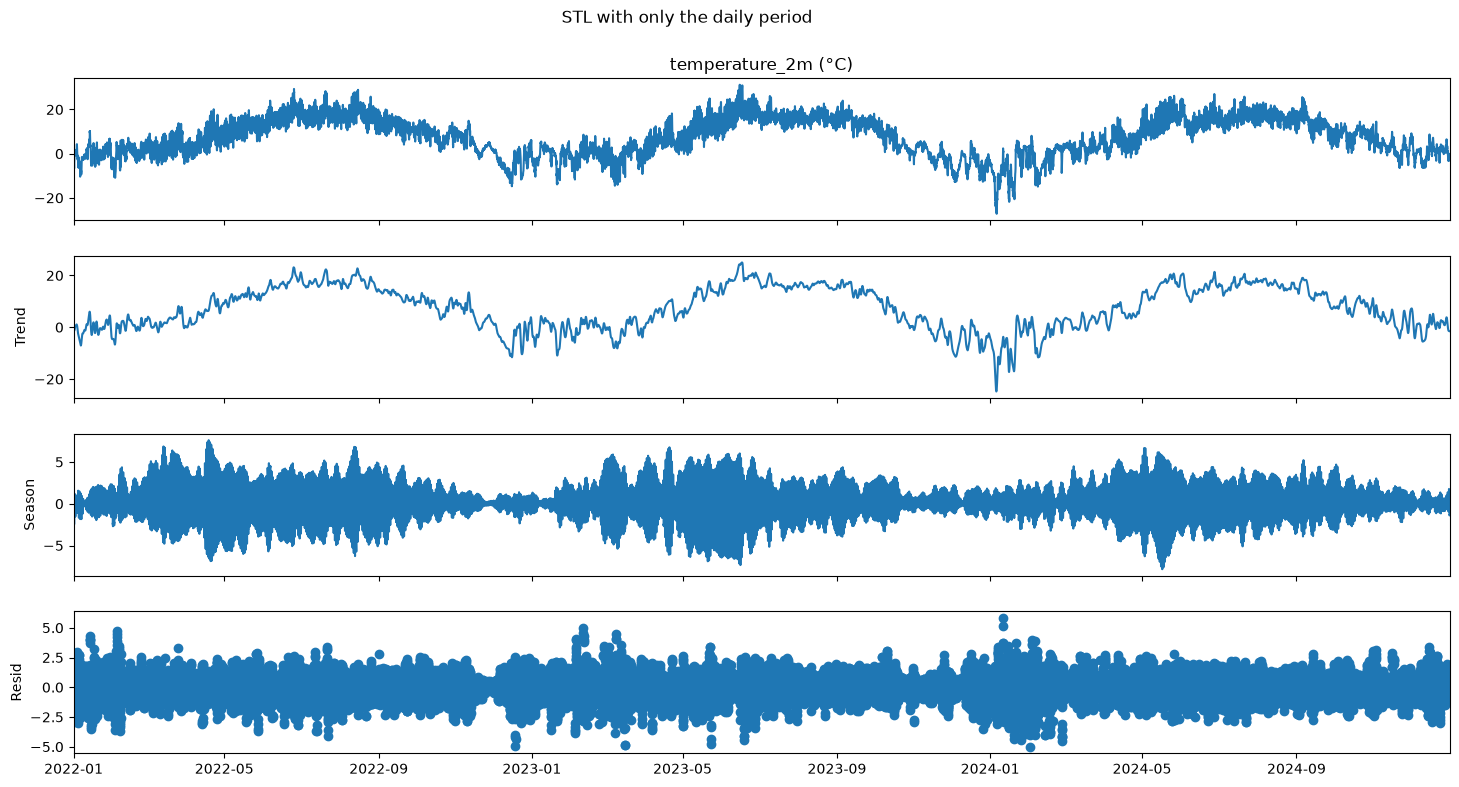

In [22]:
PERIODS = (24, 24 * 365)
STL_FAST = dict(trend_jump=24, low_pass_jump=24)
res = MSTL(yh, periods=PERIODS, stl_kwargs=STL_FAST).fit()
res1 = STL(yh, period=24).fit()

fig = res.plot()
fig.set_size_inches(16, 10)
fig.suptitle('MSTL with periods 24 h and 8760 h', y=1.01)
plt.show()
fig = res1.plot()
fig.set_size_inches(16, 8)
fig.suptitle('STL with only the daily period', y=1.01)
plt.show()

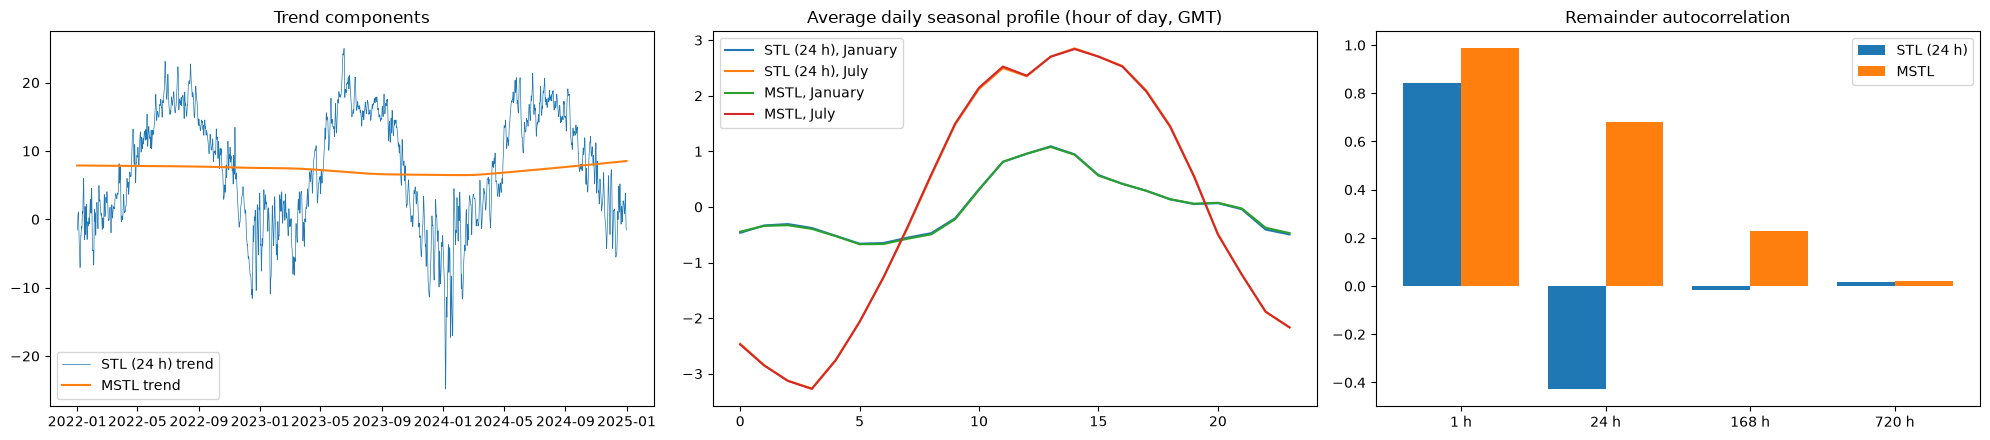

,STL (24 h),MSTL
std trend,8.259,0.550
std daily seasonal,2.159,2.104
std remainder,0.924,2.072
std yearly seasonal,NaN,8.105


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].plot(res1.trend, lw=0.5, label='STL (24 h) trend')
axes[0].plot(res.trend, lw=1.5, label='MSTL trend')
axes[0].set_title('Trend components')
axes[0].legend()
for name, r, col in [('STL (24 h)', res1, 'seasonal'), ('MSTL', res, 'seasonal_24')]:
    s = r.seasonal if col == 'seasonal' else r.seasonal[col]
    daily = s.groupby([s.index.month, s.index.hour]).mean().unstack(0)
    axes[1].plot(daily[1], label=f'{name}, January')
    axes[1].plot(daily[7], label=f'{name}, July')
axes[1].set_title('Average daily seasonal profile (hour of day, GMT)')
axes[1].legend()
acf_lag = lambda r, lag: pd.Series(r.resid).autocorr(lag)
lags = [1, 24, 24 * 7, 24 * 30]
axes[2].bar(np.arange(len(lags)) - 0.2, [acf_lag(res1, l) for l in lags], 0.4, label='STL (24 h)')
axes[2].bar(np.arange(len(lags)) + 0.2, [acf_lag(res, l) for l in lags], 0.4, label='MSTL')
axes[2].set_xticks(range(len(lags)), [f'{l} h' for l in lags])
axes[2].set_title('Remainder autocorrelation')
axes[2].legend()
plt.tight_layout()
plt.show()
pd.DataFrame({'STL (24 h)': {'std trend': res1.trend.std(), 'std daily seasonal': res1.seasonal.std(), 'std remainder': res1.resid.std()},
              'MSTL': {'std trend': res.trend.std(), 'std daily seasonal': res.seasonal['seasonal_24'].std(),
                       'std yearly seasonal': res.seasonal['seasonal_8760'].std(), 'std remainder': res.resid.std()}}).round(3)

With only the daily period, STL sends the yearly cycle into the trend (std 8.3 °C against 0.55 °C for MSTL). That trend cannot be extrapolated, and the remainder (0.92 °C) looks small only because the trend absorbs the multi-day weather. MSTL separates the yearly component and leaves the weather persistence in the remainder.

**3. Forecasting the last seven days**

In [24]:
H = 24 * 7
yh_train, yh_test = yh[:-H], yh[-H:]

# (i) seasonal naive: the same hour one day earlier, i.e. the last observed day repeated
fc_snaive = pd.Series(np.tile(yh_train[-24:].values, 7), index=yh_test.index)

# (ii) MSTL + ETS: decomposition on the training data only, ETS on the seasonally adjusted series,
# seasonal components added back (daily: last observed day repeated; yearly: same hours one year earlier)
res_train = MSTL(yh_train, periods=PERIODS, stl_kwargs=STL_FAST).fit()
y_adj = yh_train - res_train.seasonal.sum(axis=1)
ets = ExponentialSmoothing(y_adj, trend='add', damped_trend=True).fit()
n = len(yh_train)
seasonal_future = (np.tile(res_train.seasonal['seasonal_24'].values[-24:], 7)
                   + res_train.seasonal['seasonal_8760'].values[n - 8760:n - 8760 + H])
fc_mstl = pd.Series(ets.forecast(H).values + seasonal_future, index=yh_test.index)
print(ets.params_formatted[['param']].round(4).T)

       smoothing_level  smoothing_trend  initial_level  initial_trend  \
param              1.0              0.0         7.6267        -0.0115   

       damping_trend  
param         0.9928  


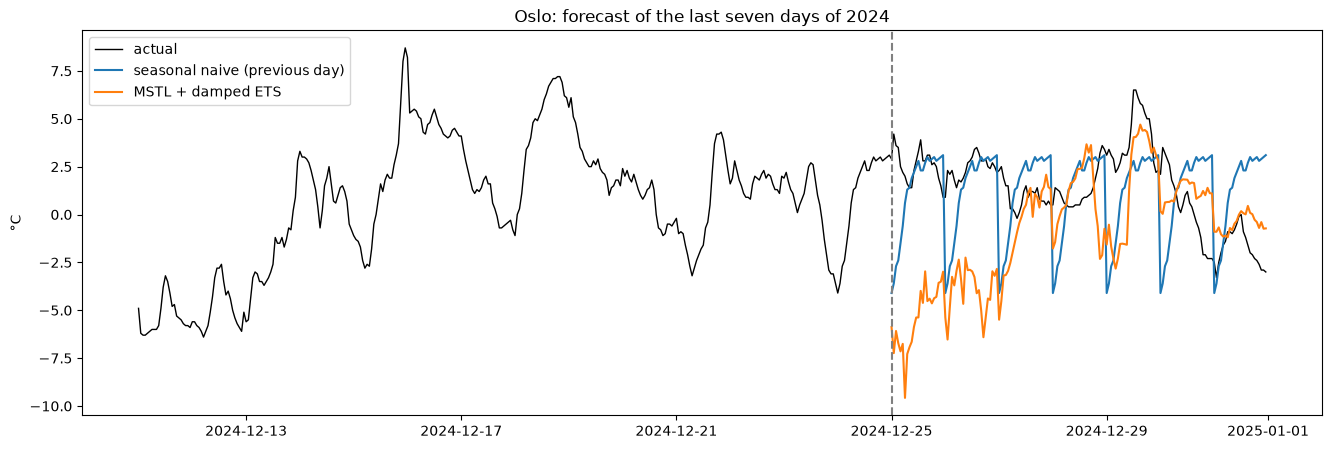

,RMSE,MAE
seasonal naive (previous day),3.118,2.413
MSTL + damped ETS,4.493,3.460


In [25]:
fc_hourly = {'seasonal naive (previous day)': fc_snaive, 'MSTL + damped ETS': fc_mstl}
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(yh[-3 * H:].index, yh[-3 * H:], color='black', lw=1, label='actual')
for name, fc in fc_hourly.items():
    ax.plot(fc.index, fc, label=name)
ax.axvline(yh_test.index[0], color='grey', ls='--')
ax.set_ylabel('°C')
ax.set_title('Oslo: forecast of the last seven days of 2024')
ax.legend()
plt.show()

pd.DataFrame({name: {'RMSE': np.sqrt(mean_squared_error(yh_test, fc)), 'MAE': mean_absolute_error(yh_test, fc)}
              for name, fc in fc_hourly.items()}).T.round(3)

Seasonal naive (RMSE 3.12) beats MSTL with ETS (4.49). The MSTL forecast starts about 9 °C too cold: with only three years, the 8,760 h component keeps the weather of those years (a cold spell around New Year 2024, averaging -16 °C on the first forecast day), while the actual week was mild (+1.4 °C). A smoother yearly component would likely help. One test week makes this ranking specific to that week.

**4. Why no weekly cycle?**

A weekly cycle in demand comes from the human work week. Temperature is driven by solar radiation (daily and yearly cycles) and by weather systems that follow no calendar, so nothing in it runs on seven days. The periodogram shows no peak at 168 h.